# TrustGuard: Complete Submission #2756 Notebook
**Team AI of Spades | DLW Datathon 2026, Track 2 | 4 October 2026**

Transaction risk ranking for a rare-fraud dataset. The report-aligned model is
**63% contextual logistic regression + 27% CatBoost + 10% tree-augmented naive Bayes (TAN)**.

This companion combines EDA, visible training implementations, fresh training,
validation, error analysis and prediction. It does not replace the submitted package.

| Evidence | Interpretation |
|---|---|
| Fresh computations in this notebook | EDA, conditional reference models, LR, TAN, optional CatBoost refit, and prediction checks |
| Fresh contextual five-fold replay | Normality donors and LR refitted; original held-out CatBoost/TAN scores retained, matching the historical experiment |
| Saved repeated evaluation | Five prior paired five-fold runs, reloaded and independently recomputed here |
| Recorded public score | #2756: 0.18900 PR-AUC; loaded from its saved receipt, not a new portal check |

The report is `inputs/technical_report_2756.pdf`. The other PDF inside the submitted ZIP
describes historical #370 and must not be confused with this model.

## 1. Reproducible Setup
The copied input snapshots make this folder portable. Run with the pinned Python 3.12
environment. Outputs are written only under `outputs/`.

By default we freshly replay five contextual validation folds and train the final
contextual LR and TAN. The original CatBoost state remains in the exact #2756 lineage;
an additional GPU refit demonstrates its training recipe but is not substituted into
the scored release, because GPU training is nondeterministic.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['NUMEXPR_NUM_THREADS'] = '2'

import hashlib, json, pickle, sys, time, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.special import logsumexp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, auc, brier_score_loss,
    confusion_matrix, log_loss, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder,
    OrdinalEncoder, StandardScaler)
from catboost import CatBoostClassifier
from catboost.utils import get_gpu_device_count
from threadpoolctl import threadpool_limits

HERE = Path.cwd()
INPUTS = HERE / 'inputs'
OUT = HERE / 'outputs'
OUT.mkdir(exist_ok=True)
RUN_FRESH_CONTEXT_CV = True
RUN_CATBOOST_TRAINING_DEMO = True
EXPECTED_VERSIONS = {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.14.1',
                     'scikit-learn': '1.5.2', 'catboost': '1.2.10'}
assert sys.version_info[:2] == (3, 12), 'Use the supplied Python 3.12 environment.'
for package, expected in EXPECTED_VERSIONS.items():
    assert version(package) == expected, (package, version(package), expected)
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 160, 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': False, 'figure.facecolor': 'white',
    'axes.facecolor': 'white'})
COLORS = {'legitimate': '#216c78', 'fraud': '#bf3547', 'train': '#216c78',
          'test': '#d78c20', 'baseline': '#6d7681', 'candidate': '#287c52'}
SHA = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
manifest = json.loads((INPUTS / 'manifest.json').read_text())
for name, record in manifest.items():
    assert SHA(INPUTS / name) == record['sha256'], f'Input changed: {name}'
protected_path = HERE / 'protected_files.json'
protected = json.loads(protected_path.read_text()) if protected_path.exists() else {}
assert all(SHA(p) == digest for p, digest in protected.items() if Path(p).exists())
checks = {'copied_inputs_verified': True, 'versions_verified': True}
display(pd.DataFrame({'package': list(EXPECTED_VERSIONS),
                      'version': list(EXPECTED_VERSIONS.values())}))

def show_figure(fig, name):
    fig.savefig(OUT / (name + '.png'), bbox_inches='tight')
    display(fig)
    plt.close(fig)

,package,version
0,numpy,2.1.3
1,pandas,2.2.3
2,scipy,1.14.1
3,scikit-learn,1.5.2
4,catboost,1.2.10


## 2. Data, Grain and Scoring-Time Assumptions
One row is one transaction. `id` is transaction lineage, not a customer identifier.
The target `fraud` is training-only. Available hour-of-day is not a full timestamp.
Country != SG is a reference-category signal, not proof of foreign travel.
Account-age units and the inclusion rules of supplied 1h/24h aggregates remain unverified.

In [2]:
train = pd.read_csv(INPUTS / 'train.csv')
test = pd.read_csv(INPUTS / 'test.csv')
RAW = [c for c in train.columns if c not in ['id', 'fraud']]
CATEGORICAL = ['merchant_category', 'country', 'transaction_channel']
NUMERIC = [c for c in RAW if c not in CATEGORICAL]
X = train[RAW].copy()
y = train.fraud.to_numpy(dtype=int)
XT = test[RAW].copy()
ids = train.id.to_numpy(str)
assert len(train) == 20000 and y.sum() == 353 and len(test) == 12000
assert train.id.is_unique and test.id.is_unique and 'fraud' not in test
assert list(test.drop(columns='id').columns) == RAW and len(RAW) == 10
assert train[RAW].duplicated().sum() == 0
prevalence = y.mean()
dictionary = pd.DataFrame({
    'field': RAW,
    'type': [str(X[c].dtype) for c in RAW],
    'training missing': [int(X[c].isna().sum()) for c in RAW],
    'test missing': [int(XT[c].isna().sum()) for c in RAW],
    'distinct training values': [int(X[c].nunique()) for c in RAW],
})
display(dictionary)
display(pd.DataFrame({'transactions': [len(train), len(test)],
    'known frauds': [int(y.sum()), 'unknown'],
    'rows with any missing predictor': [int(X.isna().any(axis=1).sum()),
                                      int(XT.isna().any(axis=1).sum())]},
    index=['training', 'test']))

,field,type,training missing,test missing,distinct training values
0,transaction_amount,float64,0,0,14134
1,transaction_hour,int64,0,0,24
2,merchant_category,object,113,259,11
3,country,object,107,268,10
4,transaction_channel,object,123,284,4
5,transactions_last_24h,float64,159,293,27
6,spend_last_24h,float64,132,267,16987
7,account_age,float64,137,264,3366
8,new_device,float64,124,293,2
9,transactions_last_1h,float64,142,245,10


,transactions,known frauds,rows with any missing predictor
training,20000,353,975
test,12000,unknown,1663


## 3. Imbalance: Why Accuracy Is a Poor Main Metric
Calling every transaction legitimate gets 98.235% accuracy and zero fraud recall.
We select rankings using local average precision (AP), and translate them into review
capacity, precision and recall. Local AP is not necessarily the portal's precise PR-AUC
integration convention.

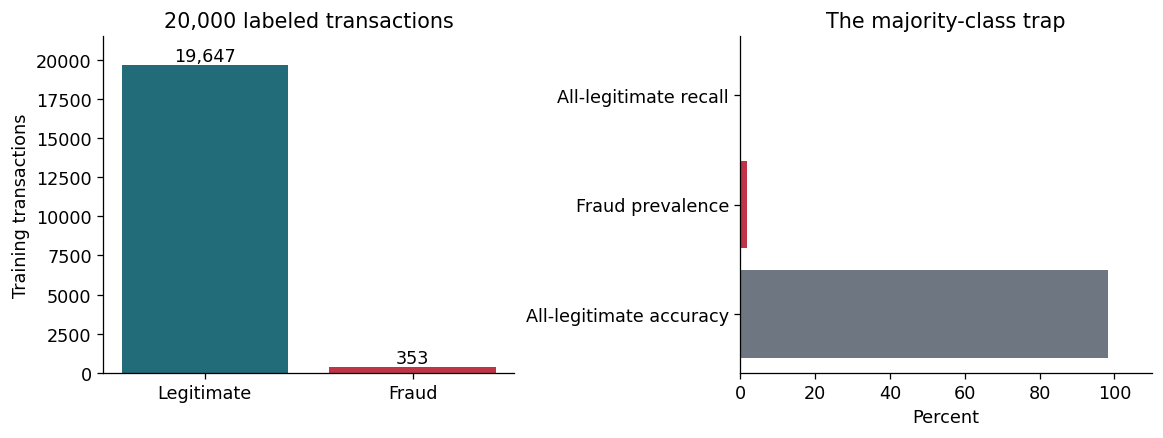

Fraud prevalence: 1.765%; constant-score AP: 0.01765


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained')
counts = np.bincount(y)
axes[0].bar(['Legitimate', 'Fraud'], counts,
            color=[COLORS['legitimate'], COLORS['fraud']])
for i, count in enumerate(counts):
    axes[0].text(i, count + 250, f'{count:,}', ha='center')
axes[0].set(ylabel='Training transactions', title='20,000 labeled transactions', ylim=(0, 21500))
axes[1].barh(['All-legitimate accuracy', 'Fraud prevalence', 'All-legitimate recall'],
    [100 * (1 - prevalence), 100 * prevalence, 0],
    color=[COLORS['baseline'], COLORS['fraud'], COLORS['fraud']])
axes[1].set(xlabel='Percent', title='The majority-class trap', xlim=(0, 110))
show_figure(fig, '01_class_imbalance')
print(f'Fraud prevalence: {prevalence:.3%}; constant-score AP: {prevalence:.5f}')

## 4. Missingness and Train/Test Shift
Retain incomplete rows. Missingness rises from 4.875% of training rows to 13.858% of test
rows. More missing values and larger amounts demonstrate input shift; they do not reveal
the hidden fraud prevalence or prove why public performance differs from CV.

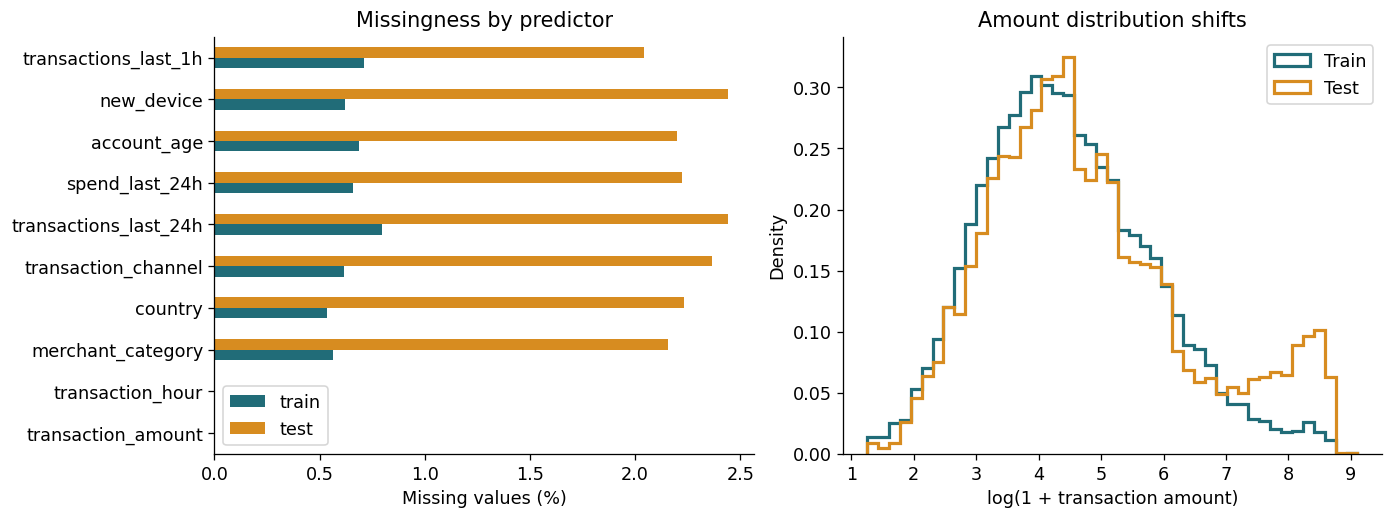

,mean amount,amount > 1000 (%),any missing predictor (%),new device among observed (%)
Train,252.664,4.915,4.875,9.056
Test,523.930,12.992,13.858,15.367


In [4]:
missing = pd.DataFrame({'train': X.isna().mean() * 100,
                        'test': XT.isna().mean() * 100})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
missing.plot.barh(ax=axes[0], color=[COLORS['train'], COLORS['test']])
axes[0].set(xlabel='Missing values (%)', ylabel='', title='Missingness by predictor')
for frame, name, color in [(X, 'Train', COLORS['train']), (XT, 'Test', COLORS['test'])]:
    axes[1].hist(np.log1p(frame.transaction_amount), bins=45, density=True,
                 histtype='step', linewidth=2, label=name, color=color)
axes[1].set(xlabel='log(1 + transaction amount)', ylabel='Density', title='Amount distribution shifts')
axes[1].legend()
show_figure(fig, '02_missingness_and_shift')
shift = pd.DataFrame({
    'mean amount': [X.transaction_amount.mean(), XT.transaction_amount.mean()],
    'amount > 1000 (%)': [(X.transaction_amount > 1000).mean() * 100,
                         (XT.transaction_amount > 1000).mean() * 100],
    'any missing predictor (%)': [X.isna().any(axis=1).mean() * 100,
                                  XT.isna().any(axis=1).mean() * 100],
    'new device among observed (%)': [X.new_device.mean() * 100, XT.new_device.mean() * 100],
}, index=['Train', 'Test'])
display(shift.round(3))

## 5. Numerical and Categorical Risk Patterns
The following are descriptive associations from the development data. They are not
causal effects, feature-selection-independent estimates, or instructions to remove
outliers. Rare categories and small joint groups have uncertain fraud rates.

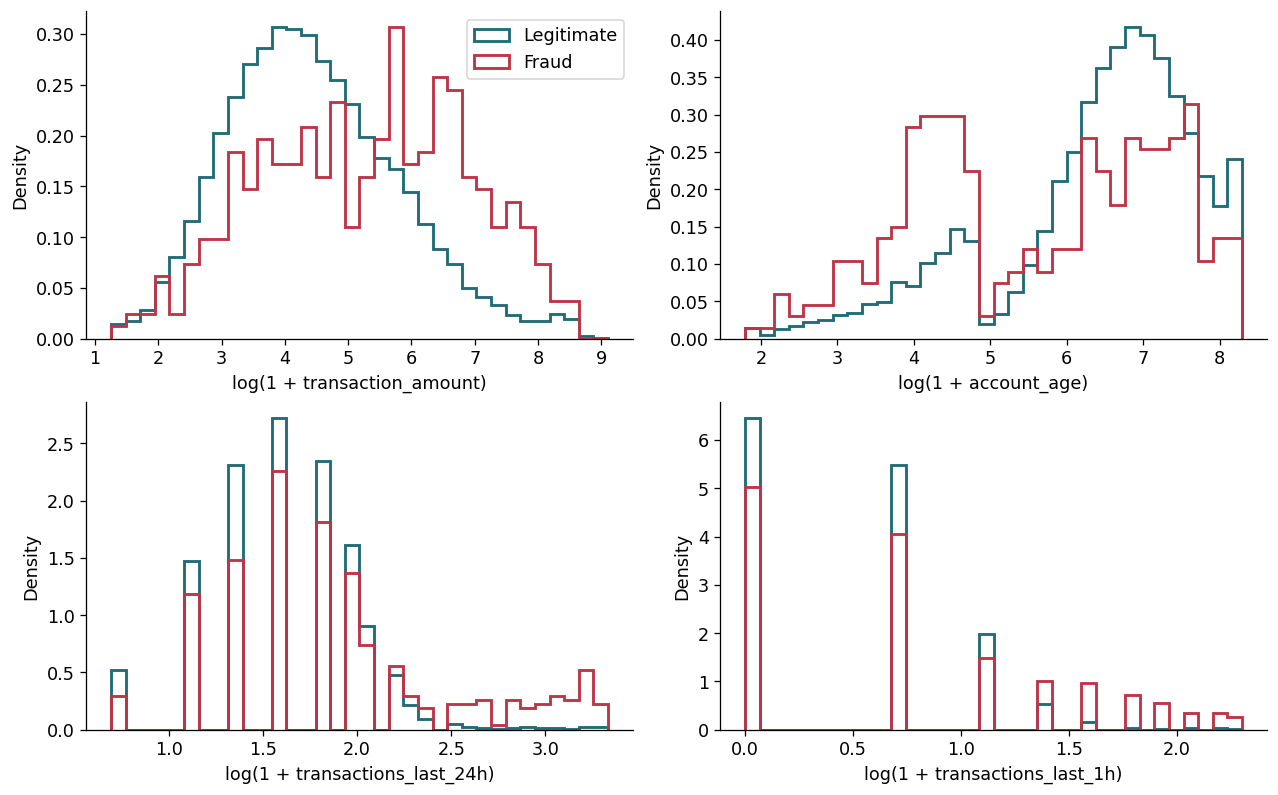

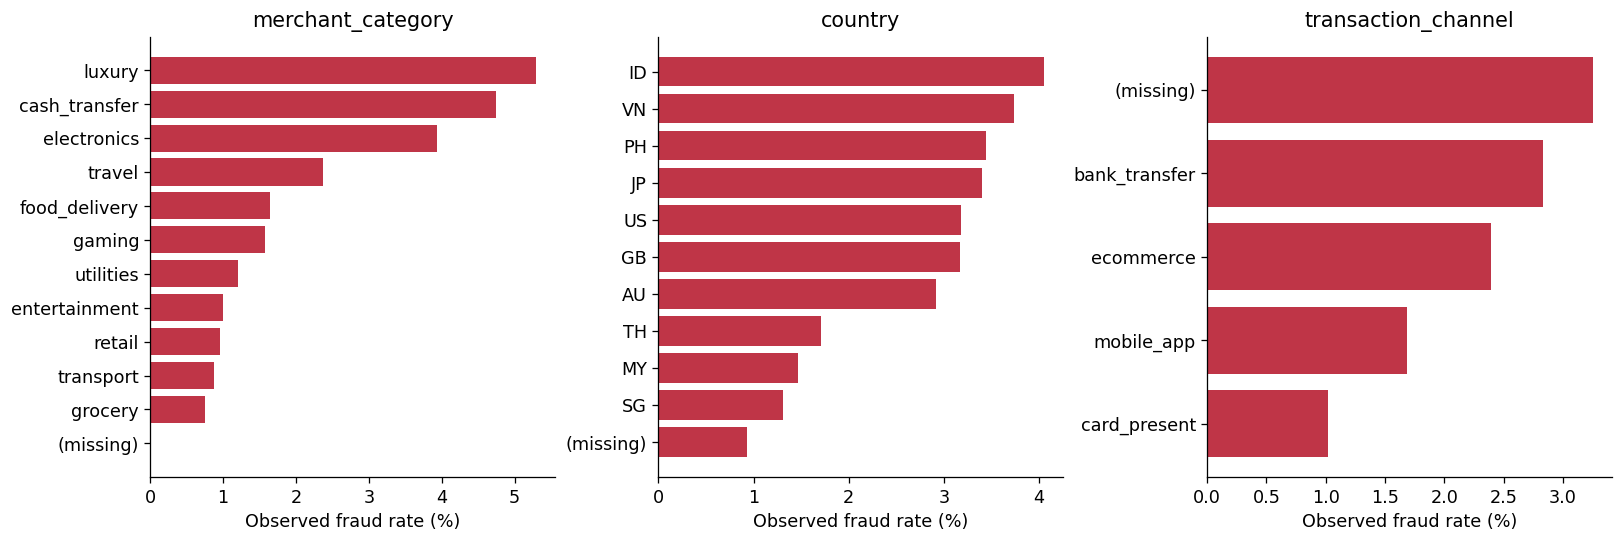

**merchant_category: rate and support**

,transactions,frauds,fraud_rate
group,,,
(missing),113,0,0.00
grocery,3566,27,0.76
transport,2387,21,0.88
retail,2601,25,0.96
entertainment,1407,14,1.00
utilities,1581,19,1.20
gaming,1339,21,1.57
food_delivery,2304,38,1.65
travel,1094,26,2.38


**country: rate and support**

,transactions,frauds,fraud_rate
group,,,
(missing),107,1,0.93
SG,13931,182,1.31
MY,1225,18,1.47
TH,644,11,1.71
AU,584,17,2.91
GB,505,16,3.17
US,693,22,3.17
JP,382,13,3.40
PH,581,20,3.44


**transaction_channel: rate and support**

,transactions,frauds,fraud_rate
group,,,
card_present,7189,73,1.02
mobile_app,5172,87,1.68
ecommerce,5507,132,2.40
bank_transfer,2009,57,2.84
(missing),123,4,3.25


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), layout='constrained')
for ax, column in zip(axes.ravel(), ['transaction_amount', 'account_age',
                                    'transactions_last_24h', 'transactions_last_1h']):
    values = np.log1p(pd.to_numeric(X[column], errors='coerce'))
    bins = np.linspace(values.min(), values.max(), 35)
    for label, name, color in [(0, 'Legitimate', COLORS['legitimate']),
                              (1, 'Fraud', COLORS['fraud'])]:
        ax.hist(values[y == label].dropna(), bins=bins, density=True,
                histtype='step', linewidth=1.8, label=name, color=color)
    ax.set(xlabel=f'log(1 + {column})', ylabel='Density')
axes[0, 0].legend()
show_figure(fig, '03_numerical_class_overlap')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout='constrained')
category_tables = {}
for ax, column in zip(axes, CATEGORICAL):
    groups = train.assign(group=train[column].fillna('(missing)')).groupby('group').fraud.agg(
        transactions='size', frauds='sum', fraud_rate='mean').sort_values('fraud_rate')
    category_tables[column] = groups
    ax.barh(groups.index, groups.fraud_rate * 100, color=COLORS['fraud'])
    ax.set(xlabel='Observed fraud rate (%)', title=column)
show_figure(fig, '04_categorical_risk')
for column, table in category_tables.items():
    display(Markdown(f'**{column}: rate and support**'))
    display(table.assign(fraud_rate=lambda z: z.fraud_rate * 100).round(2))

## 6. Joint Context and the Interaction Features
New device, account age, amount and recent activity can matter jointly. The table
below excludes missing device/age values so "older" does not silently include unknown
age. The cutoff 90 is in the supplied age units, which were not verified as days.

transactions  frauds  fraud_rate
device       age_group                                  
Known device Age < 90           2151      44       2.046
             Age >= 90         15805     172       1.088
New device   Age < 90            375      69      18.400
             Age >= 90          1410      65       4.610

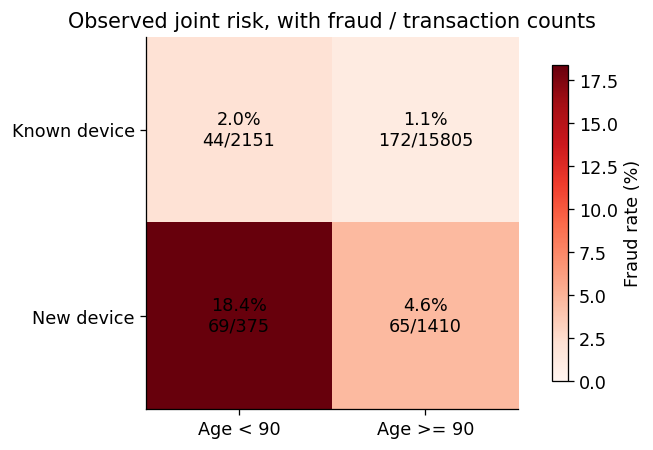

In [6]:
joint = train.dropna(subset=['new_device', 'account_age']).assign(
    device=lambda z: np.where(z.new_device == 1, 'New device', 'Known device'),
    age_group=lambda z: np.where(z.account_age < 90, 'Age < 90', 'Age >= 90'))
joint_table = joint.groupby(['device', 'age_group']).fraud.agg(
    transactions='size', frauds='sum', fraud_rate='mean')
display(joint_table.assign(fraud_rate=lambda z: z.fraud_rate * 100).round(3))
rates = joint_table.fraud_rate.unstack().reindex(
    index=['Known device', 'New device'], columns=['Age < 90', 'Age >= 90'])
fig, ax = plt.subplots(figsize=(7, 3.8), layout='constrained')
image = ax.imshow(rates.to_numpy() * 100, cmap='Reds', vmin=0)
ax.set_xticks(range(2), rates.columns)
ax.set_yticks(range(2), rates.index)
for i, device in enumerate(rates.index):
    for j, age_group in enumerate(rates.columns):
        row = joint_table.loc[(device, age_group)]
        ax.text(j, i, f'{row.fraud_rate:.1%}\n{int(row.frauds)}/{int(row.transactions)}',
                ha='center', va='center', color='black')
ax.set_title('Observed joint risk, with fraud / transaction counts')
fig.colorbar(image, ax=ax, label='Fraud rate (%)', shrink=0.85)
show_figure(fig, '05_joint_device_age')

## 7. Base Feature and Classifier Training Code
These definitions are extracted from the preserved #1486 builder, the base inherited
by #2510 and #2756. LR uses five extra interaction terms; CatBoost retains its earlier
16-input feature representation. Median imputation and numeric scaling are fitted on
training rows. Categorical one-hot columns are not standardized.

The ratio marks zero 24h count as missing before division. "Non-SG" is not a verified
customer-home-country relationship. The night flag uses hours 23, 0, 1, 2 and 3.

In [7]:
SEED = 42
CAT_COLS = ['merchant_category', 'country', 'transaction_channel']
RAW_NUM_COLS = ['transaction_amount', 'transaction_hour', 'transactions_last_24h', 'spend_last_24h', 'account_age', 'new_device', 'transactions_last_1h']
FEATURE_EXPR = "log_amount = log1p(transaction_amount)\nlog_spend_24h = log1p(spend_last_24h)\nlog_account_age = log1p(account_age)\namount_vs_avg = log1p(transaction_amount / (spend_last_24h / transactions_last_24h.replace(0, @nan) + 1))\nis_night = transaction_hour.isin([23, 0, 1, 2, 3]).astype('int64')\nis_foreign = country.notna() & (country != 'SG')\nis_foreign = is_foreign.astype('int64')"
NUM_COLS = ['transaction_hour', 'transactions_last_24h', 'new_device', 'transactions_last_1h', 'amount_vs_avg', 'log_amount', 'log_spend_24h', 'log_account_age', 'is_night', 'is_foreign']
CROSS_EXPR = 'young = account_age < 90\nnewdev_x_young = new_device * young\nnewdev_x_logamt = new_device * log_amount\nyoung_x_logamt = young * log_amount\nnewdev_x_v1h = new_device * transactions_last_1h\nnight_x_newdev = is_night * new_device'
CROSS_COLS = ['newdev_x_young', 'newdev_x_logamt', 'young_x_logamt', 'newdev_x_v1h', 'night_x_newdev']
CAT_PARAMS = {'depth': 5, 'iterations': 600, 'learning_rate': 0.042649213440561926, 'l2_leaf_reg': 29.765516351269685}
WEIGHTS = [0.7, 0.3]

def features(expr):
    return FunctionTransformer(pd.DataFrame.eval, validate=False, kw_args={'expr': expr, 'engine': 'python', 'local_dict': {'nan': np.nan}})

def make_logreg(crosses):
    expr = FEATURE_EXPR + ('\n' + CROSS_EXPR if crosses else '')
    num = NUM_COLS + (CROSS_COLS if crosses else [])
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return Pipeline([('features', features(expr)), ('preprocess', ColumnTransformer([('categorical', categorical, CAT_COLS), ('numeric', numeric, num)])), ('classifier', LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))])

def make_catboost():
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')), ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int64))])
    engineered = ['amount_vs_avg', 'log_amount', 'log_spend_24h', 'log_account_age', 'is_night', 'is_foreign']
    preprocess = ColumnTransformer([('categorical', categorical, CAT_COLS), ('numeric', 'passthrough', RAW_NUM_COLS + engineered)], sparse_threshold=0).set_output(transform='pandas')
    classifier = CatBoostClassifier(**CAT_PARAMS, loss_function='Logloss', cat_features=(0, 1, 2), border_count=128, random_seed=SEED, thread_count=2, task_type='GPU', verbose=False, allow_writing_files=False, devices='0', gpu_ram_part=0.45, pinned_memory_size='16mb', boosting_type='Plain', bootstrap_type='Bayesian', max_ctr_complexity=4)
    return Pipeline([('features', features(FEATURE_EXPR)), ('preprocess', preprocess), ('classifier', classifier)])

In [8]:
frozen = pickle.loads((INPUTS / 'frozen_2756.pkl').read_bytes())
assert frozen['format'] == 'contextual_median02_v1'
assert frozen['feature_columns'] == RAW
fresh_preprocessor = make_logreg(True)[:-1]
with threadpool_limits(2):
    A = fresh_preprocessor.fit_transform(X, y)
np.testing.assert_array_equal(A, frozen['preprocess'].transform(X))
feature_names = fresh_preprocessor[-1].get_feature_names_out()
display(pd.DataFrame({'transformed feature': feature_names}))
display(pd.DataFrame({'branch': ['Categorical indicators', 'Scaled numeric', 'Context residuals'],
                     'columns': [28, 15, 2]}))
assert A.shape == (20000, 43)
checks['fresh_base_preprocessor_exact'] = True

,transformed feature
0,categorical__merchant_category_cash_transfer
1,categorical__merchant_category_electronics
2,categorical__merchant_category_entertainment
3,categorical__merchant_category_food_delivery
4,categorical__merchant_category_gaming
5,categorical__merchant_category_grocery
6,categorical__merchant_category_luxury
7,categorical__merchant_category_missing
8,categorical__merchant_category_retail
9,categorical__merchant_category_transport


,branch,columns
0,Categorical indicators,28
1,Scaled numeric,15
2,Context residuals,2


## 8. Legitimate-Only Context Models and Nested Cross-Fitting
The normality predictors estimate conditional medians of log amount and log last-hour
count. They use legitimate-only donors with observed targets and exclude the target
from their own inputs. Context includes other log fields, categorical context, device
status and sine/cosine hour. This is population context, not personal history.

Three inner folds prevent a training row from helping fit its own normality prediction.
Two median residuals are projected off the original 43-feature design, standardized,
and scaled by 0.2 before entering the L2-regularized LR. The original code also fits
90th-quantile models, which are retained for faithful reconstruction but unused in final
prediction. These functions are embedded here with namespaced names to keep TAN and
context definitions separate.

In [9]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold
CONTEXT_TARGETS = ['transaction_amount', 'transactions_last_1h']
CONTEXT_LOG = ['transaction_amount', 'spend_last_24h', 'account_age', 'transactions_last_24h', 'transactions_last_1h']
CONTEXT_CAT = ['merchant_category', 'country', 'transaction_channel']
CONTEXT_PARAMS = {'loss': 'quantile', 'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 7, 'max_depth': 3, 'min_samples_leaf': 150, 'l2_regularization': 10.0, 'max_bins': 63, 'early_stopping': False, 'random_state': 8603}

def context_target_values(X, target):
    a = pd.to_numeric(X[target], errors='coerce').to_numpy(float)
    a = np.where(np.isfinite(a) & (a >= 0), a, np.nan)
    return np.log1p(a)

def context_features(X, target):
    F = X[CONTEXT_CAT].copy()
    for col in CONTEXT_LOG:
        if col != target:
            F['log_' + col] = context_target_values(X, col)
    F['new_device'] = pd.to_numeric(X.new_device, errors='coerce').replace([np.inf, -np.inf], np.nan)
    hr = pd.to_numeric(X.transaction_hour, errors='coerce').to_numpy(float)
    hr = np.where(np.isfinite(hr) & (hr >= 0) & (hr < 24), hr, np.nan)
    F['hour_sin'] = np.sin(2 * np.pi * hr / 24)
    F['hour_cos'] = np.cos(2 * np.pi * hr / 24)
    return F

def context_prep(F):
    return ColumnTransformer([('num', SimpleImputer(strategy='median', keep_empty_features=True), [c for c in F if c not in CONTEXT_CAT]), ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='__MISSING__', keep_empty_features=True)), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CONTEXT_CAT)])

def context_donor_fit(X, y, training, query, check):
    quantiles = np.empty((len(query), 2, 2))
    states = []
    for j, target in enumerate(CONTEXT_TARGETS):
        check()
        tv = context_target_values(X, target)
        donors = training[(y[training] == 0) & np.isfinite(tv[training])]
        assert len(donors) > 150 and (not np.intersect1d(donors, query).size)
        F = context_features(X, target)
        pre = context_prep(F)
        A = pre.fit_transform(F.iloc[donors])
        V = pre.transform(F.iloc[query])
        models = []
        for k, q in enumerate([0.5, 0.9]):
            check()
            model = HistGradientBoostingRegressor(quantile=q, **CONTEXT_PARAMS)
            model.fit(A, tv[donors])
            quantiles[:, j, k] = model.predict(V)
            models.append(model)
            check()
        states.append({'target': target, 'donors': donors, 'preprocess': pre, 'models': models, 'query': query.copy(), 'training': training.copy(), 'feature_columns': list(F.columns)})
    return (quantiles, states)

def context_crossfit(X, y, outer_train, outer_validation, check):
    qtrain = np.full((len(X), 2, 2), np.nan)
    records = []
    coverage = np.zeros(len(X), int)
    for k, (a, b) in enumerate(StratifiedKFold(3, shuffle=True, random_state=8603).split(X.iloc[outer_train], y[outer_train])):
        tr = outer_train[a]
        va = outer_train[b]
        assert not np.intersect1d(tr, outer_validation).size and (not np.intersect1d(va, outer_validation).size)
        q, states = context_donor_fit(X, y, tr, va, check)
        qtrain[va] = q
        coverage[va] += 1
        records.append({'inner_fold': k, 'training': tr, 'query': va, 'states': states})
    assert np.all(coverage[outer_train] == 1) and (not coverage[outer_validation].any())
    qval, full = context_donor_fit(X, y, outer_train, outer_validation, check)
    assert np.isfinite(qtrain[outer_train]).all() and np.isfinite(qval).all()
    return (qtrain[outer_train], qval, {'inner': records, 'full': full, 'outer_train': outer_train, 'outer_validation': outer_validation})

def context_residual_features(X, q, kind):
    t = np.column_stack([context_target_values(X, col) for col in CONTEXT_TARGETS])
    assert q.shape == (len(X), 2, 2)
    if kind == 'MEDIAN':
        return t - q[:, :, 0]
    assert kind == 'UPPER'
    return np.clip(np.maximum((t - q[:, :, 1]) / np.maximum(q[:, :, 1] - q[:, :, 0], 0.25), 0), 0, 10)

def context_fit_basis(N, A):
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    Z = imp.fit_transform(N)
    D = np.column_stack([np.ones(len(A)), A])
    projection = np.linalg.lstsq(D, Z, rcond=1e-12)[0]
    R = Z - D @ projection
    keep = R.std(0) > 1e-08
    scaler = StandardScaler().fit(R[:, keep]) if keep.any() else None
    return (scaler.transform(R[:, keep]) if scaler else np.empty((len(A), 0)), {'imputer': imp, 'projection': projection, 'keep': keep, 'scaler': scaler})

def context_transform_basis(N, A, b):
    if b['scaler'] is None:
        return np.empty((len(A), 0))
    R = b['imputer'].transform(N) - np.column_stack([np.ones(len(A)), A]) @ b['projection']
    return b['scaler'].transform(R[:, b['keep']])

## 9. TAN Training and Exact Missing-Value Inference
TAN estimates class-conditional discrete probabilities with one feature-parent per
node. Its dependency tree is learned from training-only conditional information.
Numeric fields use up to four bins; last-hour count has two effective states on the
full dataset. Smoothing strength is 80. The saved recipe uses exact missing-value
marginalization and 20 regularized EM iterations. Missingness is not assumed harmless.

The full training and message-passing implementation is embedded below, not loaded from
an opaque training script.

In [10]:
"""Small discrete NB/TAN, with exact tree marginalization. No file/data loading."""
import itertools
import numpy as np
import pandas as pd
from scipy.special import logsumexp
TAN_RAW = ['transaction_amount', 'transaction_hour', 'merchant_category', 'country', 'transaction_channel', 'transactions_last_24h', 'spend_last_24h', 'account_age', 'new_device', 'transactions_last_1h']
TAN_CAT = {'merchant_category', 'country', 'transaction_channel'}
TAN_MENU = [('NB4', None, 'marginal'), ('TAN4-M20', 20.0, 'marginal'), ('TAN4-M80', 80.0, 'marginal'), ('TAN4-S20', 20.0, 'state')]

def tan_fit_encoder(frame, mode):
    state = []
    for name in TAN_RAW:
        s = frame[name]
        item = {'name': name, 'missing_mode': mode}
        if name in TAN_CAT:
            levels = sorted(s.dropna().astype(str).unique().tolist())
            item.update(kind='category', levels=levels, value_states=max(1, len(levels)))
        elif name == 'transaction_hour':
            item.update(kind='hour', value_states=4)
        elif name == 'new_device':
            item.update(kind='binary', value_states=2)
        else:
            values = pd.to_numeric(s, errors='coerce').to_numpy(float)
            values = values[np.isfinite(values)]
            cuts = np.unique(np.quantile(values, [0.25, 0.5, 0.75], method='linear')) if len(values) else np.array([])
            if len(values):
                cuts = cuts[cuts > values.min()]
            if len(values) and len(cuts):
                occupied = np.unique(np.searchsorted(cuts, values, side='right'))
                cuts = cuts[occupied[1:] - 1]
                np.testing.assert_array_equal(np.unique(np.searchsorted(cuts, values, side='right')), np.arange(len(cuts) + 1))
            item.update(kind='numeric', cuts=cuts, value_states=len(cuts) + 1)
        item['states'] = item['value_states'] + (mode == 'state')
        state.append(item)
    return state

def tan_encode(frame, state):
    out = np.full((len(frame), len(state)), -1, dtype=np.int64)
    for i, item in enumerate(state):
        s = frame[item['name']]
        missing = s.isna().to_numpy()
        kind = item['kind']
        if kind == 'category':
            mapping = {v: j for j, v in enumerate(item['levels'])}
            out[:, i] = s.map(lambda v: mapping.get(str(v), -1) if not pd.isna(v) else -1).to_numpy(int)
        else:
            a = pd.to_numeric(s, errors='coerce').to_numpy(float)
            ok = np.isfinite(a)
            if kind == 'numeric':
                out[ok, i] = np.searchsorted(item['cuts'], a[ok], side='right')
            elif kind == 'hour':
                ok &= (a >= 0) & (a < 24)
                out[ok, i] = np.floor((a[ok] + 3) % 24 / 6).astype(int)
            else:
                ok &= (a == 0) | (a == 1)
                out[ok, i] = a[ok].astype(int)
        if item['missing_mode'] == 'state':
            out[missing, i] = item['value_states']
    return out

def tan_marginals(x, y, ks):
    result = []
    for i, k in enumerate(ks):
        ok = x[:, i] >= 0
        count = np.bincount(y[ok] * k + x[ok, i], minlength=2 * k).reshape(2, k)
        result.append((count + 1.0 / k) / (count.sum(1, keepdims=True) + 1.0))
    return result

def tan_learn_tree(x, y, ks, m, prior):
    d = len(ks)
    edges = []
    support = {}
    for i in range(d):
        for j in range(i + 1, d):
            ok = (x[:, i] >= 0) & (x[:, j] >= 0)
            n = np.bincount(y[ok] * ks[i] * ks[j] + x[ok, i] * ks[j] + x[ok, j], minlength=2 * ks[i] * ks[j]).reshape(2, ks[i], ks[j])
            q = n + 20.0 * m[i][:, :, None] * m[j][:, None, :]
            q /= q.sum((1, 2), keepdims=True)
            information = (q * np.log(q / (q.sum(2, keepdims=True) * q.sum(1, keepdims=True)))).sum((1, 2))
            score = float(np.dot(prior, information))
            edges.append((score, i, j))
            support[f'{i},{j}'] = {'pair_observed_class_counts': n.sum((1, 2)).tolist(), 'pair_table_counts': n, 'weight': score}
    component = list(range(d))
    chosen = []

    def find(a):
        while component[a] != a:
            a = component[a]
        return a
    for weight, i, j in sorted(edges, key=lambda row: (-row[0], row[1], row[2])):
        a, b = (find(i), find(j))
        if a != b:
            component[b] = a
            chosen.append((i, j))
        if len(chosen) == d - 1:
            break
    adjacency = [[] for _ in range(d)]
    for i, j in chosen:
        adjacency[i].append(j)
        adjacency[j].append(i)
    parent = np.full(d, -2, int)
    parent[1] = -1
    queue = [1]
    for i in queue:
        for j in sorted(adjacency[i]):
            if parent[j] == -2:
                parent[j] = i
                queue.append(j)
    assert (parent != -2).all()
    return (parent, support)

def tan_postorder(parent):
    children = [[] for _ in parent]
    for i, p in enumerate(parent):
        if p >= 0:
            children[p].append(i)
    order = []

    def visit(i):
        for j in children[i]:
            visit(j)
        order.append(i)
    for i, p in enumerate(parent):
        if p < 0:
            visit(i)
    assert len(order) == len(parent) and len(set(order)) == len(parent)
    return (order, children)

def tan_validate(model):
    k = model['ks']
    parent = model['parent']
    tan_postorder(parent)
    assert len(k) == len(parent) == len(model['probability'])
    np.testing.assert_allclose(model['prior'].sum(), 1.0, rtol=0, atol=1e-14)
    assert np.all(model['prior'] > 0)
    for i, t in enumerate(model['probability']):
        assert t.shape == ((2, k[i]) if parent[i] < 0 else (2, k[parent[i]], k[i]))
        assert np.isfinite(t).all() and np.all(t > 0)
        np.testing.assert_allclose(t.sum(-1), 1.0, rtol=0, atol=1e-13)

def tan_log_evidence(model, x):
    """Exact evidence likelihood for arbitrary observed subsets and either class."""
    x = np.asarray(x, dtype=np.int64)
    ks = model['ks']
    parent = model['parent']
    assert x.ndim == 2 and x.shape[1] == len(ks)
    assert all((np.all((x[:, i] >= -1) & (x[:, i] < k)) for i, k in enumerate(ks)))
    order, children = tan_postorder(parent)
    answer = np.zeros((len(x), 2))
    for c in range(2):
        messages = {}
        for i in order:
            local = np.zeros((len(x), ks[i]))
            known = x[:, i] >= 0
            local[known, :] = -np.inf
            local[np.flatnonzero(known), x[known, i]] = 0.0
            for child in children[i]:
                local += messages[child]
            t = np.log(model['probability'][i][c])
            if parent[i] < 0:
                answer[:, c] += logsumexp(local + t, axis=1)
            else:
                messages[i] = logsumexp(local[:, None, :] + t[None, :, :], axis=2)
    return answer

def tan_predict_encoded(model, x):
    lp = tan_log_evidence(model, x) + np.log(model['prior'])
    return np.exp(lp - logsumexp(lp, axis=1, keepdims=True))

def tan_predict_proba(model, frame):
    return tan_predict_encoded(model, tan_encode(frame, model['encoder']))

def tan_complete_log_likelihood(model, x, y):
    out = np.zeros(len(x))
    for i, p in enumerate(model['parent']):
        t = model['probability'][i]
        out += np.log(t[y, x[:, i]] if p < 0 else t[y, x[:, p], x[:, i]])
    return out

def tan_expand_missing(x, ks, max_rows=100000):
    count = np.ones(len(x), dtype=int)
    for i, k in enumerate(ks):
        count *= np.where(x[:, i] < 0, k, 1)
    if count.sum() > max_rows:
        raise RuntimeError('Exact training completion resource cap exceeded')
    original = np.repeat(np.arange(len(x)), count)
    expanded = x[original].copy()
    start = np.r_[0, np.cumsum(count)[:-1]]
    for row in np.flatnonzero(count > 1):
        missing = np.flatnonzero(x[row] < 0)
        states = np.array(list(itertools.product(*(range(ks[j]) for j in missing))), int)
        expanded[start[row]:start[row] + count[row], missing] = states
    expanded[expanded < 0] = 0
    return (expanded, original, start)

def tan_e_step(model, expanded, original, start, y):
    lp = tan_complete_log_likelihood(model, expanded, y[original])
    maximum = np.maximum.reduceat(lp, start)
    scaled = np.exp(lp - maximum[original])
    normalizer = np.add.reduceat(scaled, start)
    weight = scaled / normalizer[original]
    likelihood = float(np.sum(maximum + np.log(normalizer) + np.log(model['prior'][y])))
    return (weight, likelihood)

def tan_m_step(model, expanded, y, weight, tau, centers):
    tables = []
    support = []
    for i, p in enumerate(model['parent']):
        ki = model['ks'][i]
        if p < 0:
            count = np.bincount(y * ki + expanded[:, i], weights=weight, minlength=2 * ki).reshape(2, ki)
            table = (count + 1.0 / ki) / (count.sum(1, keepdims=True) + 1.0)
        else:
            kp = model['ks'][p]
            count = np.bincount(y * kp * ki + expanded[:, p] * ki + expanded[:, i], weights=weight, minlength=2 * kp * ki).reshape(2, kp, ki)
            table = (count + tau * centers[i][:, None, :]) / (count.sum(2, keepdims=True) + tau)
        tables.append(table)
        support.append(count)
    return (tables, support)

def tan_regularizer(model, tau, centers):
    value = 0.0
    for i, p in enumerate(model['parent']):
        log = np.log(model['probability'][i])
        value += float(np.sum(log / model['ks'][i])) if p < 0 else float(np.sum(tau * centers[i][:, None, :] * log))
    return value

def tan_fit_encoded(x, y, ks, structure, tau=20.0, iterations=20):
    """Fit only supplied encoded data; callers must enforce outer isolation."""
    x = np.asarray(x, int)
    y = np.asarray(y, int)
    ks = np.asarray(ks, int)
    assert set(np.unique(y)) == {0, 1}
    prior = np.bincount(y, minlength=2) / len(y)
    centers = tan_marginals(x, y, ks)
    parent, scores = (np.full(len(ks), -1, int), {}) if structure == 'nb' else tan_learn_tree(x, y, ks, centers, prior)
    model = {'format': 'tan_discrete_v1', 'positive_class': 1, 'ks': ks, 'parent': parent, 'prior': prior, 'probability': [], 'pair_scores': scores, 'prior_centers': centers, 'tau': tau, 'trace': []}
    model['observed_state_counts'] = []
    for i, k in enumerate(ks):
        ok = x[:, i] >= 0
        model['observed_state_counts'].append(np.bincount(y[ok] * k + x[ok, i], minlength=2 * k).reshape(2, k))
    for i, p in enumerate(parent):
        if p < 0:
            model['probability'].append(centers[i].copy())
            continue
        ki, kp = (ks[i], ks[p])
        ok = (x[:, i] >= 0) & (x[:, p] >= 0)
        count = np.bincount(y[ok] * kp * ki + x[ok, p] * ki + x[ok, i], minlength=2 * kp * ki).reshape(2, kp, ki)
        model['probability'].append((count + tau * centers[i][:, None, :]) / (count.sum(2, keepdims=True) + tau))
    if structure != 'nb':
        expanded, original, start = tan_expand_missing(x, ks)
        weights, ll = tan_e_step(model, expanded, original, start, y)
        objective = ll + tan_regularizer(model, tau, centers)
        model['trace'].append({'iteration': 0, 'log_likelihood': ll, 'regularized_objective': objective})
        for step in range(iterations):
            tables, support = tan_m_step(model, expanded, y[original], weights, tau, centers)
            delta = max((float(np.max(np.abs(a - b))) for a, b in zip(tables, model['probability'])))
            model['probability'] = tables
            weights, ll = tan_e_step(model, expanded, original, start, y)
            new = ll + tan_regularizer(model, tau, centers)
            assert new >= objective - 1e-06, (step, objective, new)
            model['trace'].append({'iteration': step + 1, 'log_likelihood': ll, 'regularized_objective': new, 'max_parameter_change': delta})
            objective = new
        model['final_m_step_support'] = support if iterations else None
        _, support = tan_m_step(model, expanded, y[original], weights, tau, centers)
        model['expected_support'] = support
        model['expanded_training_rows'] = len(expanded)
    tan_validate(model)
    return model

def tan_fit(frame, y, spec):
    name, tau, mode = spec
    encoder = tan_fit_encoder(frame, mode)
    x = tan_encode(frame, encoder)
    structure = 'nb' if name == 'NB4' else 'tan'
    model = tan_fit_encoded(x, y, [s['states'] for s in encoder], structure, tau or 20.0, 20 if mode == 'marginal' and structure == 'tan' else 0)
    model.update(name=name, encoder=encoder)
    return model

## 10. Fresh TAN Fit and CatBoost Training Demonstration
TAN is refitted below using training data only and compared with the retained state.
The additional CatBoost GPU training demonstrates the historical recipe. The original
#2756 build did not refit CatBoost, so the released branch is retained when reconstructing
#2756. A new GPU fit is a separate model instance and need not match its old weights.

In [11]:
started = time.perf_counter()
with threadpool_limits(2):
    fresh_tan_full = tan_fit(X, y, ('TAN4-M80', 80., 'marginal'))
fresh_tan = {key: fresh_tan_full[key] for key in
             ['encoder', 'ks', 'parent', 'prior', 'probability', 'positive_class']}
fresh_tan_test = tan_predict_proba(fresh_tan, XT)[:, 1]
frozen_tan_test = tan_predict_proba(frozen['tan'], XT)[:, 1]
np.testing.assert_array_equal(fresh_tan_test, frozen_tan_test)
checks['fresh_tan_exact'] = True
display(pd.DataFrame(fresh_tan_full['trace']).tail())
print(f'TAN refit: {time.perf_counter() - started:.2f}s; retained-state predictions exact.')
display(pd.DataFrame({'feature': RAW, 'states': fresh_tan['ks'],
    'parent': ['class only' if p < 0 else RAW[p] for p in fresh_tan['parent']]}))

catboost_demo = None
catboost_demo_receipt = {'executed': False, 'used_in_2756_reconstruction': False}
if RUN_CATBOOST_TRAINING_DEMO:
    if get_gpu_device_count() == 0:
        raise RuntimeError('Historical CatBoost recipe requires GPU. Disable only the optional demo to replay #2756 on CPU.')
    started = time.perf_counter()
    catboost_demo = make_catboost()
    with threadpool_limits(2):
        catboost_demo.fit(X, y)
        demo_scores = catboost_demo.predict_proba(XT)[:, 1]
    catboost_demo_receipt = {'executed': True, 'training_rows': len(X),
        'training_frauds': int(y.sum()), 'task_type': 'GPU',
        'seconds': time.perf_counter() - started,
        'max_difference_from_retained_catboost': float(np.max(np.abs(
            demo_scores - frozen['cat_pipeline'].predict_proba(XT)[:, 1]))),
        'used_in_2756_reconstruction': False}
    with (OUT / 'catboost_training_demo.pkl').open('wb') as handle:
        pickle.dump(catboost_demo, handle, protocol=5)
display(pd.DataFrame([catboost_demo_receipt]))

,iteration,log_likelihood,regularized_objective,max_parameter_change
16,16,-237042.646338,-253440.837847,0.0
17,17,-237042.646338,-253440.837847,0.0
18,18,-237042.646338,-253440.837847,0.0
19,19,-237042.646338,-253440.837847,0.0
20,20,-237042.646338,-253440.837847,0.0


TAN refit: 1.60s; retained-state predictions exact.


,feature,states,parent
0,transaction_amount,4,merchant_category
1,transaction_hour,4,class only
2,merchant_category,11,country
3,country,10,transaction_hour
4,transaction_channel,4,merchant_category
5,transactions_last_24h,4,spend_last_24h
6,spend_last_24h,4,merchant_category
7,account_age,4,merchant_category
8,new_device,2,account_age
9,transactions_last_1h,2,transactions_last_24h


,executed,training_rows,training_frauds,task_type,seconds,max_difference_from_retained_catboost,used_in_2756_reconstruction
0,True,20000,353,GPU,22.213236,0.0,False


## 11. Fresh Five-Fold Contextual Validation Replay
Outer split: stratified five-fold, seed 17. Inner normality split: three-fold, seed 8603.
Fresh donor models, preprocessing, residual projection and LR are fitted only inside
each outer training fold. This recreates the historical experiment, which retained
already held-out CatBoost and TAN fold predictions. Their IDs and fold assignments
are verified before reuse. This is a fresh contextual replay, not newly retrained
CatBoost/TAN cross-validation and not independent new data.

In [12]:
saved = np.load(INPUTS / 'confirmation_oof.npz', allow_pickle=False)
np.testing.assert_array_equal(saved['id'], ids)
np.testing.assert_array_equal(saved['label'], y)
folds = list(StratifiedKFold(5, shuffle=True, random_state=17).split(X, y))
for k, (tr, va) in enumerate(folds):
    assert np.all(saved['fold'][va] == k)
assert np.isfinite(saved['cat_oof']).all() and np.isfinite(saved['TAN_oof']).all()
fresh_lr_oof = np.full(len(y), np.nan)
fold_records = []
if RUN_FRESH_CONTEXT_CV:
    started = time.perf_counter()
    deadline = time.monotonic() + 1800
    def cv_check():
        if time.monotonic() > deadline:
            raise TimeoutError('Fresh contextual CV exceeded the 30-minute bound.')
    for k, (tr, va) in enumerate(folds):
        with threadpool_limits(2):
            qt, qv, donor_state = context_crossfit(X, y, tr, va, cv_check)
            pre = make_logreg(True)[:-1]
            a = pre.fit_transform(X.iloc[tr], y[tr])
            v = pre.transform(X.iloc[va])
            r, basis = context_fit_basis(context_residual_features(X.iloc[tr], qt, 'MEDIAN'), a)
            w = context_transform_basis(context_residual_features(X.iloc[va], qv, 'MEDIAN'), v, basis)
            classifier = clone(make_logreg(True)[-1])
            with warnings.catch_warnings():
                warnings.simplefilter('error', ConvergenceWarning)
                classifier.fit(np.column_stack([a, 0.2 * r]), y[tr])
            fresh_lr_oof[va] = classifier.predict_proba(np.column_stack([v, 0.2 * w]))[:, 1]
        assert all(np.all(y[state['donors']] == 0) and
            np.intersect1d(state['donors'], va).size == 0
            for record in donor_state['inner'] for state in record['states'])
        fold_records.append({'fold': k + 1, 'training_rows': len(tr),
            'validation_rows': len(va), 'validation_frauds': int(y[va].sum()),
            'contextual_LR_AP': average_precision_score(y[va], fresh_lr_oof[va]),
            'max_LR_difference_vs_saved': float(np.max(np.abs(
                fresh_lr_oof[va] - saved['MEDIAN_0.2_lr'][va])))})
        print(f'Contextual validation fold {k + 1}/5 complete', flush=True)
    np.testing.assert_allclose(fresh_lr_oof, saved['MEDIAN_0.2_lr'], rtol=0, atol=1e-10)
    cv_origin = 'Fresh contextual replay; retained held-out CatBoost/TAN components'
    checks['fresh_contextual_cv_reproduced'] = True
    print(f'Fresh contextual CV elapsed: {time.perf_counter() - started:.1f}s')
else:
    fresh_lr_oof = saved['MEDIAN_0.2_lr'].copy()
    cv_origin = 'Saved development OOF scores, recomputed only; no new fold fits'
    checks['fresh_contextual_cv_reproduced'] = False
oof = 0.63 * fresh_lr_oof + 0.27 * saved['cat_oof'] + 0.10 * saved['TAN_oof']
np.testing.assert_allclose(oof, saved['MEDIAN_0.2'], rtol=0, atol=1e-10)
np.savez_compressed(OUT / 'contextual_validation_replay.npz', id=ids, label=y,
                   fold=saved['fold'], contextual_lr=fresh_lr_oof, prediction=oof)
display(pd.DataFrame(fold_records))
print(cv_origin)

Contextual validation fold 1/5 complete


Contextual validation fold 2/5 complete


Contextual validation fold 3/5 complete


Contextual validation fold 4/5 complete


Contextual validation fold 5/5 complete


Fresh contextual CV elapsed: 46.6s


,fold,training_rows,validation_rows,validation_frauds,contextual_LR_AP,max_LR_difference_vs_saved
0,1,16000,4000,70,0.218386,0.0
1,2,16000,4000,70,0.314188,0.0
2,3,16000,4000,71,0.166411,0.0
3,4,16000,4000,71,0.252709,0.0
4,5,16000,4000,71,0.272860,0.0


Fresh contextual replay; retained held-out CatBoost/TAN components


## 12. Model Comparison, AP and Precision-Recall
This matched comparison shares one split and the same labels. It does not combine
unmatched scores from different studies. AP is the recall-weighted precision summary;
trapezoidal PR area is reported separately. A foldwise mean and pooled OOF AP are also
different statistics.

,pooled OOF AP
model,
Contextual LR,0.234906
CatBoost,0.205888
TAN,0.142070
Previous #2510,0.236337
Blend #2756,0.236493


,AP,PR_trapezoid,ROC_AUC,log_loss,Brier
0,0.236493,0.235528,0.784344,0.072133,0.015053


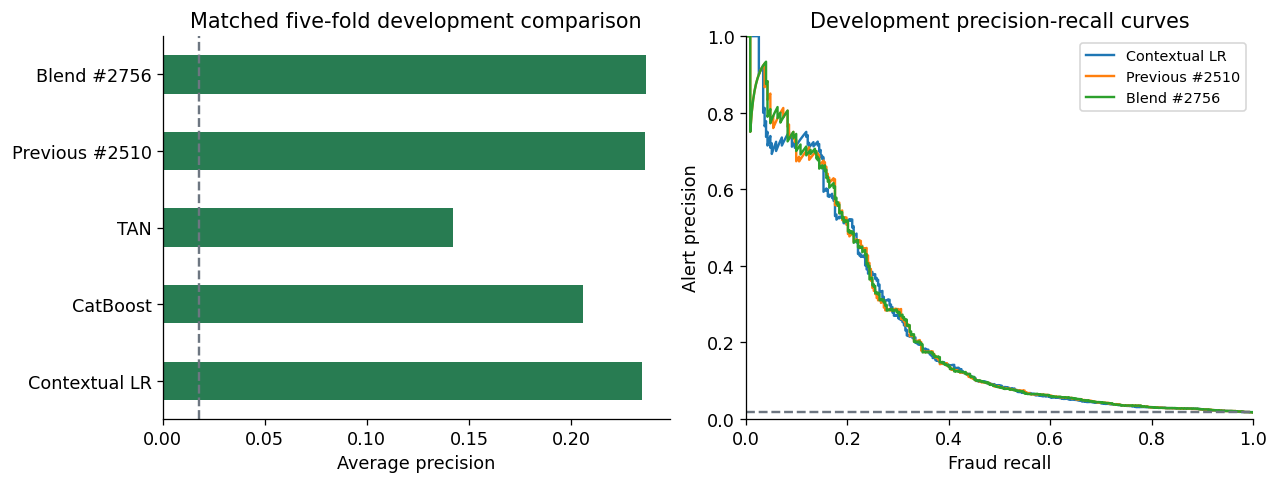

In [13]:
components = {'Contextual LR': fresh_lr_oof, 'CatBoost': saved['cat_oof'],
              'TAN': saved['TAN_oof'], 'Previous #2510': saved['baseline2510'],
              'Blend #2756': oof}
comparison = pd.DataFrame([{'model': name, 'pooled OOF AP': average_precision_score(y, p)}
                          for name, p in components.items()]).set_index('model')
display(comparison.round(9))
precision, recall, thresholds = precision_recall_curve(y, oof)
metrics = {'AP': float(average_precision_score(y, oof)),
    'PR_trapezoid': float(auc(recall, precision)), 'ROC_AUC': float(roc_auc_score(y, oof)),
    'log_loss': float(log_loss(y, oof)), 'Brier': float(brier_score_loss(y, oof))}
assert abs(metrics['AP'] - 0.2364934878513279) < 1e-10
display(pd.DataFrame([metrics]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout='constrained')
comparison['pooled OOF AP'].plot.barh(ax=axes[0], color=COLORS['candidate'])
axes[0].axvline(prevalence, color=COLORS['baseline'], linestyle='--', label='Constant score')
axes[0].set(xlabel='Average precision', ylabel='', title='Matched five-fold development comparison')
for name in ['Contextual LR', 'Previous #2510', 'Blend #2756']:
    pr, rc, _ = precision_recall_curve(y, components[name])
    axes[1].plot(rc, pr, label=name, linewidth=1.5)
axes[1].axhline(prevalence, color=COLORS['baseline'], linestyle='--')
axes[1].set(xlabel='Fraud recall', ylabel='Alert precision', title='Development precision-recall curves',
            xlim=(0, 1), ylim=(0, 1))
axes[1].legend(fontsize=9)
show_figure(fig, '06_models_and_precision_recall')

## 13. Investigator Review Capacity and Thresholds
Risk ranking is translated into explicit workload. These estimates use development
OOF predictions; no testing labels exist. The notebook emits continuous scores, not
automatic blocking decisions. The best-F1 cutoff below is selected on reused labels
and is not a validated production policy. Exact thresholds matter: rounding changes
the confusion counts.

,reviewed,budget (%),frauds caught,legitimate alerts,precision (%),recall (%),precision lift
0,100,0.5,61,39,61.0,17.280,34.561
1,200,1.0,84,116,42.0,23.796,23.796
2,1000,5.0,141,859,14.1,39.943,7.989


,exact development cutoff,TP,FP,FN,TN,precision,recall,F1
0,0.193767,83,105,270,19542,0.441489,0.235127,0.306839


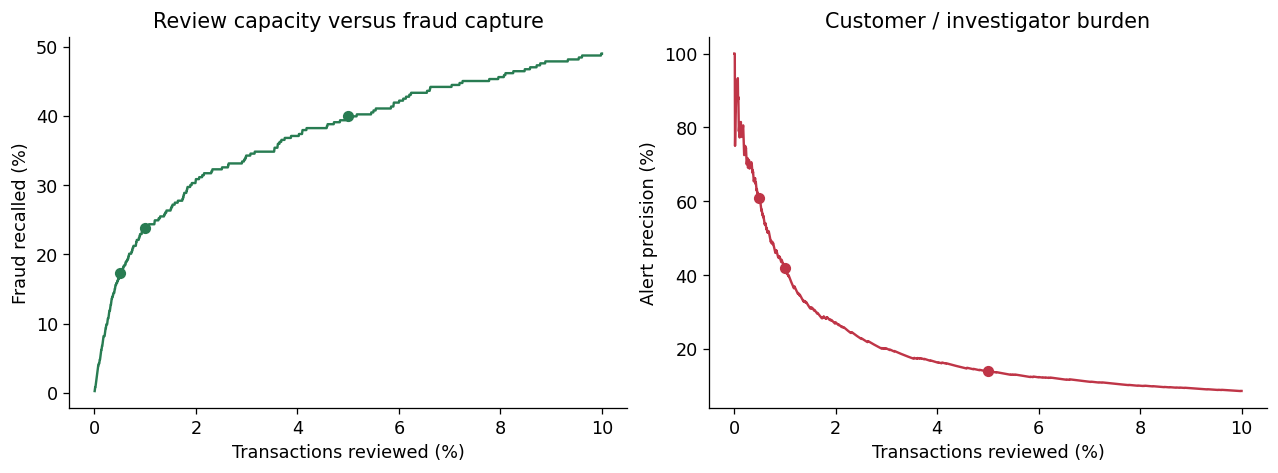

In [14]:
order = np.argsort(-oof, kind='stable')
budget_rows = []
for count in [100, 200, 1000]:
    caught = int(y[order[:count]].sum())
    budget_rows.append({'reviewed': count, 'budget (%)': count / len(y) * 100,
        'frauds caught': caught, 'legitimate alerts': count - caught,
        'precision (%)': caught / count * 100, 'recall (%)': caught / y.sum() * 100,
        'precision lift': (caught / count) / prevalence})
budget_table = pd.DataFrame(budget_rows)
display(budget_table.round(3))
assert budget_table['frauds caught'].tolist() == [61, 84, 141]
f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
best_threshold = float(thresholds[np.argmax(f1_values)])
tn, fp, fn, tp = confusion_matrix(y, oof >= best_threshold).ravel()
threshold_record = {'exact development cutoff': best_threshold, 'TP': int(tp), 'FP': int(fp),
    'FN': int(fn), 'TN': int(tn), 'precision': float(tp / (tp + fp)),
    'recall': float(tp / (tp + fn)), 'F1': float(2 * tp / (2 * tp + fp + fn))}
display(pd.DataFrame([threshold_record]))
budgets = np.arange(1, 2001)
captured = np.cumsum(y[order])[:len(budgets)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].plot(budgets / len(y) * 100, captured / y.sum() * 100, color=COLORS['candidate'])
axes[0].set(xlabel='Transactions reviewed (%)', ylabel='Fraud recalled (%)', title='Review capacity versus fraud capture')
axes[1].plot(budgets / len(y) * 100, captured / budgets * 100, color=COLORS['fraud'])
axes[1].set(xlabel='Transactions reviewed (%)', ylabel='Alert precision (%)', title='Customer / investigator burden')
for row in budget_rows:
    axes[0].scatter(row['budget (%)'], row['recall (%)'], color=COLORS['candidate'])
    axes[1].scatter(row['budget (%)'], row['precision (%)'], color=COLORS['fraud'])
show_figure(fig, '07_review_capacity')

## 14. Error Analysis and Probability Calibration Boundary
Known-device fraud is difficult, and AP must be interpreted against each segment's
own prevalence. Small missing-data groups cannot establish that missingness is
uninformative. The reliability plot is descriptive on reused OOF data; no calibration
mapping is fitted, and calibration under deployment shift is not established.

,rows,frauds,prevalence,AP
segment,,,,
All,20000,353,0.01765,0.23649
Known device,18076,218,0.01206,0.04904
New device,1800,135,0.07500,0.51213
Complete,19025,333,0.01750,0.23102
Incomplete,975,20,0.02051,0.34329


At the development F1 cutoff: 270 missed frauds; 215 have a known device.


,mean_score,observed_fraud,transactions,frauds
bin,,,,
"(0.00035000000000000005, 0.00387]",0.00319,0.0040,2000,8
"(0.00387, 0.00485]",0.00436,0.0060,2000,12
"(0.00485, 0.00581]",0.00533,0.0040,2000,8
"(0.00581, 0.00696]",0.00638,0.0050,2000,10
"(0.00696, 0.00836]",0.00764,0.0130,2000,26
"(0.00836, 0.0103]",0.00930,0.0070,2000,14
"(0.0103, 0.0132]",0.01162,0.0125,2000,25
"(0.0132, 0.0179]",0.01528,0.0130,2000,26
"(0.0179, 0.0284]",0.02232,0.0255,2000,51


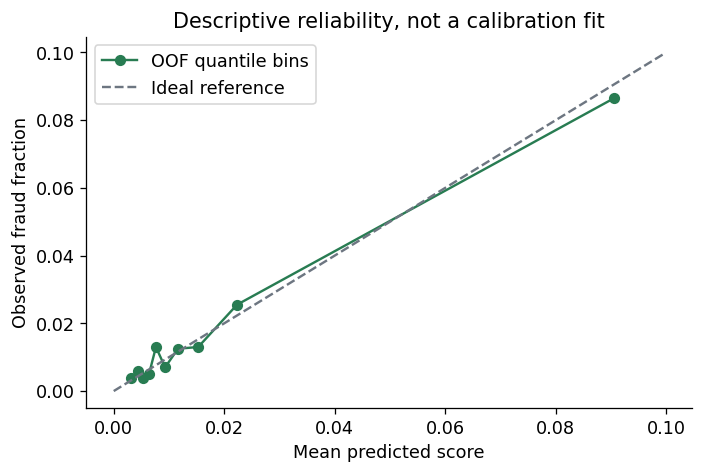

In [15]:
masks = {'All': np.ones(len(y), dtype=bool), 'Known device': X.new_device.eq(0).to_numpy(),
         'New device': X.new_device.eq(1).to_numpy(),
         'Complete': ~X.isna().any(axis=1).to_numpy(),
         'Incomplete': X.isna().any(axis=1).to_numpy()}
slice_rows = []
for name, mask in masks.items():
    slice_rows.append({'segment': name, 'rows': int(mask.sum()), 'frauds': int(y[mask].sum()),
        'prevalence': float(y[mask].mean()), 'AP': float(average_precision_score(y[mask], oof[mask]))})
display(pd.DataFrame(slice_rows).set_index('segment').round(5))
alerts = oof >= best_threshold
false_negatives = train.loc[(y == 1) & ~alerts, RAW]
print(f'At the development F1 cutoff: {len(false_negatives)} missed frauds; '
      f'{int(false_negatives.new_device.eq(0).sum())} have a known device.')
calibration = pd.DataFrame({'score': oof, 'fraud': y}).assign(
    bin=lambda z: pd.qcut(z.score, 10, duplicates='drop')).groupby('bin', observed=True).agg(
        mean_score=('score', 'mean'), observed_fraud=('fraud', 'mean'),
        transactions=('fraud', 'size'), frauds=('fraud', 'sum'))
display(calibration.round(5))
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
ax.plot(calibration.mean_score, calibration.observed_fraud, 'o-', color=COLORS['candidate'], label='OOF quantile bins')
upper = max(calibration.mean_score.max(), calibration.observed_fraud.max()) * 1.1
ax.plot([0, upper], [0, upper], '--', color=COLORS['baseline'], label='Ideal reference')
ax.set(xlabel='Mean predicted score', ylabel='Observed fraud fraction', title='Descriptive reliability, not a calibration fit')
ax.legend()
show_figure(fig, '08_reliability')

## 15. Repeated Validation and Honest Selection History
The original contextual source study failed its gate. A separately written post-source
follow-up gained only 0.000156643 AP on the five-fold split. Later repeated checks did
not support consistent superiority. New seeds reuse the same 353 labels and are not
untouched validation. Report sample spread descriptively, not as independent-fold
confidence intervals.

The newer PDF's "0.233 averaged over 25 repeated folds" should be read as the mean of
**five pooled repeat APs**, not the arithmetic mean of 25 fold APs. A public gain does
not erase the negative repeated comparison.

,seed,#2510 pooled AP,#2756 pooled AP,change,folds won
0,37,0.233633,0.232580,-0.001053,1
1,107,0.231564,0.229041,-0.002522,1
2,211,0.238815,0.239292,0.000477,4
3,503,0.236684,0.235850,-0.000834,2
4,1009,0.229011,0.228352,-0.000659,0


,candidate_mean_pooled_AP,baseline_mean_pooled_AP,mean_paired_change,repeat_wins,individual_fold_wins,candidate_repeat_SD
0,0.233023,0.233941,-0.000918,1,8,0.004614


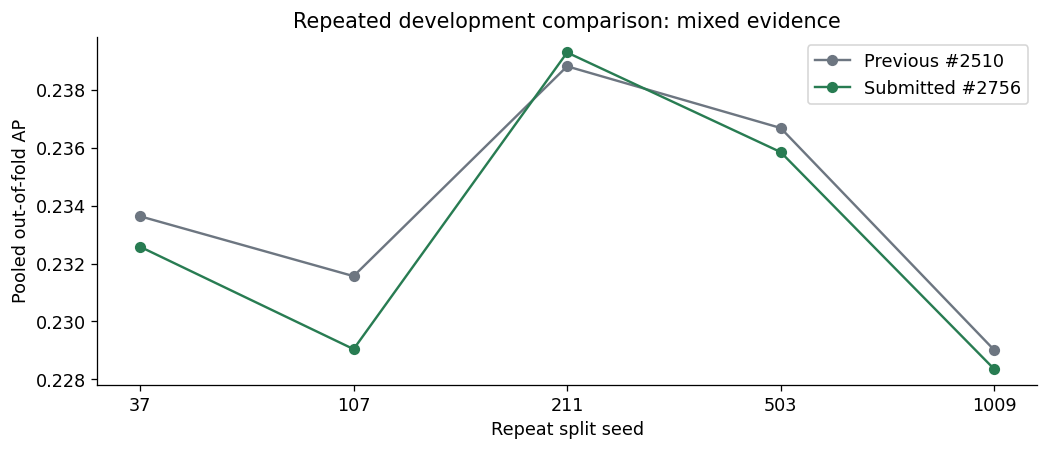

,submission,recorded public PR-AUC,previous public PR-AUC,boundary
0,2756,0.189,0.18776,Saved historical public receipt; hidden-final ...


In [16]:
repeat_rows = []
for seed in [37, 107, 211, 503, 1009]:
    z = np.load(INPUTS / f'repeat_{seed}.npz', allow_pickle=False)
    np.testing.assert_array_equal(z['id'], ids)
    np.testing.assert_array_equal(z['label'], y)
    baseline_ap = average_precision_score(y, z['baseline2510'])
    candidate_ap = average_precision_score(y, z['candidate2756'])
    fold_changes = [average_precision_score(y[z['fold'] == k], z['candidate2756'][z['fold'] == k])
        - average_precision_score(y[z['fold'] == k], z['baseline2510'][z['fold'] == k]) for k in range(5)]
    repeat_rows.append({'seed': seed, '#2510 pooled AP': baseline_ap,
        '#2756 pooled AP': candidate_ap, 'change': candidate_ap - baseline_ap,
        'folds won': int(np.sum(np.asarray(fold_changes) > 0))})
repeat_table = pd.DataFrame(repeat_rows)
display(repeat_table.round(9))
repeat_summary = {'candidate_mean_pooled_AP': float(repeat_table['#2756 pooled AP'].mean()),
    'baseline_mean_pooled_AP': float(repeat_table['#2510 pooled AP'].mean()),
    'mean_paired_change': float(repeat_table.change.mean()),
    'repeat_wins': int((repeat_table.change > 0).sum()),
    'individual_fold_wins': int(repeat_table['folds won'].sum()),
    'candidate_repeat_SD': float(repeat_table['#2756 pooled AP'].std(ddof=1))}
assert abs(repeat_summary['candidate_mean_pooled_AP'] - 0.2330231153410128) < 1e-12
assert repeat_summary['repeat_wins'] == 1 and repeat_summary['individual_fold_wins'] == 8
display(pd.DataFrame([repeat_summary]))
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
ax.plot(range(5), repeat_table['#2510 pooled AP'], 'o-', color=COLORS['baseline'], label='Previous #2510')
ax.plot(range(5), repeat_table['#2756 pooled AP'], 'o-', color=COLORS['candidate'], label='Submitted #2756')
ax.set_xticks(range(5), repeat_table.seed.astype(str))
ax.set(xlabel='Repeat split seed', ylabel='Pooled out-of-fold AP', title='Repeated development comparison: mixed evidence')
ax.legend()
show_figure(fig, '09_repeated_validation')
public_receipt = json.loads((INPUTS / 'public_result.json').read_text())
display(pd.DataFrame([{'submission': public_receipt['submission_id'],
    'recorded public PR-AUC': public_receipt['public_PR_AUC'],
    'previous public PR-AUC': public_receipt['previous_best_public_PR_AUC'],
    'boundary': 'Saved historical public receipt; hidden-final score unknown'}]))

## 16. Train the Full #2756 Contextual Model
This faithfully follows the #2756 export: three-fold cross-fitted training residuals,
full legitimate-only reference fits for future inputs, training-fitted base preprocessing
and residual projection, and one C=0.1 LR fit. The newly fitted, parity-checked TAN state
is used; the original CatBoost branch is retained. Test predictors are queried only
after donor fits and never used to fit preprocessing, donors or the classifier.

Only medians are used at inference. The new residual columns are scaled by 0.2.
They are learned conditional adjustments, not a monotonic rule that anomaly means fraud.

In [17]:
started = time.perf_counter()
deadline = time.monotonic() + 1800
def training_check():
    if time.monotonic() > deadline:
        raise TimeoutError('Full contextual training exceeded the 30-minute bound.')
qt = np.full((len(X), 2, 2), np.nan)
coverage = np.zeros(len(X), dtype=int)
donor_rows = []
with threadpool_limits(2):
    for k, (tr, va) in enumerate(StratifiedKFold(3, shuffle=True, random_state=8603).split(X, y)):
        q, states = context_donor_fit(X, y, tr, va, training_check)
        qt[va] = q
        coverage[va] += 1
        for state in states:
            assert np.all(y[state['donors']] == 0)
            assert np.intersect1d(state['donors'], va).size == 0
            donor_rows.append({'inner fold': k + 1, 'target': state['target'],
                               'legitimate donors': len(state['donors']), 'query rows': len(va)})
        print(f'Full-training cross-fit {k + 1}/3 complete', flush=True)
    assert np.all(coverage == 1) and np.isfinite(qt).all()
    combined = pd.concat([X, XT], ignore_index=True)
    qtest, normal_states = context_donor_fit(combined, y, np.arange(len(X)),
        np.arange(len(X), len(X) + len(XT)), training_check)
    pre = make_logreg(True)[:-1]
    a = pre.fit_transform(X, y)
    v = pre.transform(XT)
    r, basis = context_fit_basis(context_residual_features(X, qt, 'MEDIAN'), a)
    classifier = clone(make_logreg(True)[-1])
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        classifier.fit(np.column_stack([a, 0.2 * r]), y)
assert r.shape == (20000, 2)
reconstructed = {'format': 'contextual_median02_v1', 'feature_columns': RAW,
    'normal_models': [{'target': state['target'], 'preprocess': state['preprocess'],
                      'models': state['models']} for state in normal_states],
    'preprocess': pre, 'basis': basis, 'classifier': classifier,
    'cat_pipeline': frozen['cat_pipeline'], 'tan': fresh_tan,
    'metadata': {**frozen['metadata'], 'notebook_reconstruction': True,
                 'CatBoost_retained_from_release': True, 'TAN_freshly_refitted': True}}
with (OUT / 'training_reconstruction.pkl').open('wb') as handle:
    pickle.dump(reconstructed, handle, protocol=5)
display(pd.DataFrame(donor_rows))
display(pd.DataFrame({'contextual residual': CONTEXT_TARGETS,
    'LR coefficient on scaled input': classifier.coef_[0, -2:],
    'effective log-odds change per standardized unit': 0.2 * classifier.coef_[0, -2:]}))
full_training_seconds = time.perf_counter() - started
print(f'Full contextual fit: {full_training_seconds:.1f}s; 16 quantile reference fits, one LR fit.')

Full-training cross-fit 1/3 complete


Full-training cross-fit 2/3 complete


Full-training cross-fit 3/3 complete


,inner fold,target,legitimate donors,query rows
0,1,transaction_amount,13098,6667
1,1,transactions_last_1h,13010,6667
2,2,transaction_amount,13098,6667
3,2,transactions_last_1h,13009,6667
4,3,transaction_amount,13098,6666
5,3,transactions_last_1h,12999,6666


,contextual residual,LR coefficient on scaled input,effective log-odds change per standardized unit
0,transaction_amount,-0.004900,-0.000980
1,transactions_last_1h,-0.170618,-0.034124


Full contextual fit: 22.4s; 16 quantile reference fits, one LR fit.


## 17. Prediction, Serialization and Release Parity
The function below mirrors the submitted notebook. It selects the ten predictor
columns, uses fitted state only and applies the fixed 63/27/10 probability blend.
The test set has no labels, so these checks validate execution and reproduction,
not test detection performance. Both canonical and freshly reconstructed scores
are exported under separate filenames.

In [18]:
def predict_components(bundle, frame):
    missing = set(bundle['feature_columns']) - set(frame.columns)
    if missing:
        raise ValueError(f'Missing required input columns: {sorted(missing)}')
    x = frame[bundle['feature_columns']]
    medians = []
    for state in bundle['normal_models']:
        context = context_features(x, state['target'])
        encoded = state['preprocess'].transform(context)
        medians.append(state['models'][0].predict(encoded))
    q50 = np.column_stack(medians)
    targets = np.column_stack([context_target_values(x, name) for name in CONTEXT_TARGETS])
    a = bundle['preprocess'].transform(x)
    residual = context_transform_basis(targets - q50, a, bundle['basis'])
    lr = bundle['classifier'].predict_proba(np.column_stack([a, 0.2 * residual]))[:, 1]
    cat = bundle['cat_pipeline'].predict_proba(x)[:, 1]
    tan = tan_predict_proba(bundle['tan'], x)[:, 1]
    return {'LR': lr, 'CatBoost': cat, 'TAN': tan,
            'prediction': 0.63 * lr + 0.27 * cat + 0.10 * tan}

def predict_fraud(bundle, frame):
    scores = predict_components(bundle, frame)['prediction']
    if len(scores) != len(frame) or not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError('Invalid fraud probabilities')
    return scores

with threadpool_limits(2):
    release_scores = predict_fraud(frozen, XT)
    reconstruction_scores = predict_fraud(reconstructed, XT)
    reloaded = pickle.loads((OUT / 'training_reconstruction.pkl').read_bytes())
    reloaded_scores = predict_fraud(reloaded, XT)
expected = pd.read_csv(INPUTS / 'frozen_submission.csv', float_precision='round_trip')
np.testing.assert_array_equal(expected.id.to_numpy(str), test.id.to_numpy(str))
np.testing.assert_array_equal(release_scores, expected.prediction.to_numpy())
np.testing.assert_allclose(reconstruction_scores, release_scores, rtol=0, atol=1e-10)
np.testing.assert_array_equal(reloaded_scores, reconstruction_scores)
for name, scores in [('predictions_reproduced_2756.csv', release_scores),
                     ('predictions_training_reconstruction.csv', reconstruction_scores)]:
    pd.DataFrame({'id': test.id, 'prediction': scores}).to_csv(OUT / name, index=False, float_format='%.17g')
pd.DataFrame({'prediction': release_scores}).to_csv(OUT / 'sandbox_predictions_2756.csv', index=False, float_format='%.17g')
checks.update(canonical_predictions_exact=True,
              fresh_training_predictions_reproduced=True, serialization_exact=True)
reconstruction_max_difference = float(np.abs(reconstruction_scores - release_scores).max())
display(pd.DataFrame([{'test rows': len(XT), 'canonical max CSV difference': 0.0,
    'fresh training max difference': reconstruction_max_difference,
    'score minimum': release_scores.min(), 'score maximum': release_scores.max()}]))

,test rows,canonical max CSV difference,fresh training max difference,score minimum,score maximum
0,12000,0.0,0.0,0.001712,0.884578


## 18. Shuffled Input, Single Transactions and Unknown Categories
The scoring contract requires shuffled input without IDs and one prediction per input
row. These checks use the freshly reconstructed model and compare aligned scores.
Unseen categories must not change the feature width or crash encoding. No threshold,
retraining or query-batch fitting occurs during prediction.

In [19]:
permutation = np.random.default_rng(2756).permutation(len(XT))
with threadpool_limits(2):
    shuffled_scores = predict_fraud(reconstructed, test.iloc[permutation].drop(columns='id'))
    singleton_scores = np.array([predict_fraud(reconstructed, XT.iloc[[i]])[0]
                                  for i in permutation[:6]])
    small_scores = predict_fraud(reconstructed, XT.iloc[permutation[:37]])
    unknown = XT.iloc[:3].copy()
    for column in CATEGORICAL:
        unknown[column] = '__UNSEEN_FOR_PRESENTATION_CHECK__'
    unknown_scores = predict_fraud(reconstructed, unknown)
np.testing.assert_allclose(shuffled_scores, reconstruction_scores[permutation], rtol=0, atol=1e-12)
np.testing.assert_allclose(singleton_scores, reconstruction_scores[permutation[:6]], rtol=0, atol=1e-12)
np.testing.assert_allclose(small_scores, reconstruction_scores[permutation[:37]], rtol=0, atol=1e-12)
assert np.isfinite(unknown_scores).all() and ((unknown_scores >= 0) & (unknown_scores <= 1)).all()
checks.update(shuffled_no_ID_passed=True, singleton_passed=True,
              small_batch_passed=True, unknown_categories_passed=True)
display(pd.DataFrame({'check': ['Shuffled no-ID input', 'Six singleton transactions', '37-row subset', 'Unknown categories'],
    'result': ['passed', 'passed', 'passed', 'finite valid scores']}))

,check,result
0,Shuffled no-ID input,passed
1,Six singleton transactions,passed
2,37-row subset,passed
3,Unknown categories,finite valid scores


## 19. Report Alignment, Limitations and Finals Narrative
| Report claim | Defensible interpretation |
|---|---|
| 0.2365 held-out five-fold AP | Out-of-fold development AP, not an untouched external holdout |
| 0.233 over 25 repeated folds | Mean of five pooled repeat AP values; the predecessor averaged slightly higher |
| Rules written before results | Per-experiment rules existed; this contextual follow-up was explicitly post-source and exploratory |
| Account age below 90 days | Below 90 in supplied units; the unit was not verified |
| Probability / verification policy | Probability estimates are emitted; calibration, OTP effectiveness and blocking policy are unverified |
| Verified package | Local reproduction and saved Linux checks; separate from organizer acceptance or private evaluation |

At the 1% development review budget, 84 frauds are prioritized alongside 116 legitimate
alerts, while 269 frauds remain outside that queue. Most fraud is not caught at that
budget. Customer history, timestamps and richer identifiers are unavailable. Input
shift and repeated reuse of the same labels limit generalization claims.

**Suggested finals story:** explain the investigator's capacity and the accuracy trap,
show context and interactions, describe the three branches, present review-budget
results, distinguish local AP from recorded public PR-AUC, and acknowledge the mixed
contextual evidence. The next step is prospective future-time validation and a
capacity/cost-based policy, not an unverified automatic block threshold.

References: [scikit-learn AP](https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.average_precision_score.html),
[Logistic regression](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html),
[CatBoost categorical processing](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic).
Source snapshots and saved receipts are in `inputs/manifest.json`.

## 20. Completion Receipt and Protected Files
The receipt distinguishes fresh training from retained components and saved historical
evidence. It verifies input identities and that the original submission files were
unchanged. Fresh local checks do not imply a new leaderboard submission or final score.

In [20]:
assert all(SHA(INPUTS / name) == record['sha256'] for name, record in manifest.items())
originals_verified = {p: SHA(p) == digest for p, digest in protected.items() if Path(p).exists()}
assert all(originals_verified.values())
checks['original_submission_unchanged'] = all(originals_verified.values())
receipt = {'passed': all(value for key, value in checks.items()
    if key != 'fresh_contextual_cv_reproduced' or RUN_FRESH_CONTEXT_CV),
    'checks': checks, 'python': sys.version, 'versions': EXPECTED_VERSIONS,
    'fresh_contextual_cv': RUN_FRESH_CONTEXT_CV, 'CV_evidence_origin': cv_origin,
    'fresh_full_training': {'normal_reference_fits': 16, 'LR_fits': 1,
        'TAN_fits': 1, 'CatBoost_retained': True, 'seconds': full_training_seconds},
    'CatBoost_training_demo': catboost_demo_receipt,
    'fresh_training_max_difference_from_release': reconstruction_max_difference,
    'development_metrics': metrics, 'review_budget': budget_rows,
    'development_threshold': threshold_record, 'saved_repeated_validation': repeat_summary,
    'recorded_public_PR_AUC': public_receipt['public_PR_AUC'],
    'protected_files_verified': originals_verified,
    'boundary': 'Local training/prediction reproduction; saved development/public evidence; no upload or hidden-test claim'}
(OUT / 'verification_receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False) + '\n')
assert receipt['passed']
display(pd.DataFrame({'check': list(checks), 'passed': list(checks.values())}))
print('Complete: EDA, training, validation, prediction and preservation checks passed.')

,check,passed
0,copied_inputs_verified,True
1,versions_verified,True
2,fresh_base_preprocessor_exact,True
3,fresh_tan_exact,True
4,fresh_contextual_cv_reproduced,True
5,canonical_predictions_exact,True
6,fresh_training_predictions_reproduced,True
7,serialization_exact,True
8,shuffled_no_ID_passed,True
9,singleton_passed,True


Complete: EDA, training, validation, prediction and preservation checks passed.
